In [1]:
from google.colab import files

uploaded = files.upload()

Saving test_data.csv to test_data.csv
Saving train_data.csv to train_data.csv


In [13]:
import pandas as pd
import numpy as np

train_df = pd.read_csv("train_data.csv")
test_df = pd.read_csv("test_data.csv")

X_train = train_df.drop(columns=["Churn"])
y_train = train_df["Churn"]

X_test = test_df.drop(columns=["Churn"])
y_test = test_df["Churn"]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

display(train_df.head())

Training data: (5634, 19)
Testing data: (1409, 19)

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Male,0,No,No,35,No,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.20,1701.65,0
1,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,75.10,1151.55,0
2,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Mailed check,40.55,590.35,0
3,Female,0,Yes,No,26,Yes,No,DSL,No,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.50,1905.70,0
4,Male,0,Yes,Yes,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,44.55,44.55,0


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Combine preprocessing and model into one pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [16]:
# Predict churn classes
y_pred = logistic_model.predict(X_test)

# Predict probability of churn (class 1)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Actual labels:", y_test.iloc[:10].tolist())
print("Predicted labels:", y_pred[:10].tolist())
print("Churn probabilities:", y_prob[:10].round(3).tolist())

Actual labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]
Predicted labels: [0, 1, 0, 0, 0, 1, 0, 0, 0, 0]
Churn probabilities: [0.045, 0.684, 0.059, 0.402, 0.022, 0.604, 0.449, 0.13, 0.003, 0.395]


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

Accuracy : 0.8055
Precision: 0.6572
Recall   : 0.5588
F1-score : 0.604
ROC-AUC  : 0.8419

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



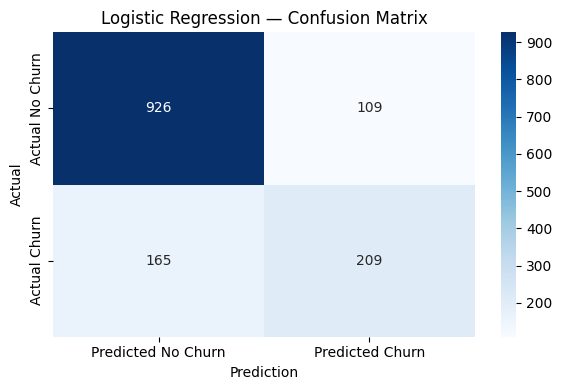

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted No Churn", "Predicted Churn"],
    yticklabels=["Actual No Churn", "Actual Churn"]
)

plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Model 2: Decision Tree
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=10,
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

print("Decision Tree training completed!")


# Model 3: Random Forest
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Decision Tree training completed!
Random Forest training completed!


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results).round(4)

display(
    results_df.sort_values(
        by="F1-score",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8419
1,Decision Tree,0.7984,0.6347,0.5668,0.5989,0.8282
2,Random Forest,0.8041,0.6690,0.5187,0.5843,0.8428


In [19]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results).round(4)

display(
    cv_results_df.sort_values(
        "F1-score",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8021,0.6529,0.5431,0.5923,0.8461
2,Random Forest,0.8042,0.6730,0.5130,0.5818,0.8463
1,Decision Tree,0.7911,0.6325,0.5144,0.5652,0.8290


In [11]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate out-of-fold probabilities on training data
oof_prob = cross_val_predict(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

threshold_results = []

for threshold in np.arange(0.20, 0.71, 0.05):
    pred = (oof_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_train, pred, zero_division=0),
        "Recall": recall_score(y_train, pred, zero_division=0),
        "F1-score": f1_score(y_train, pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results).round(4)

display(threshold_df)

,Threshold,Precision,Recall,F1-score
0,0.20,0.4751,0.8548,0.6108
1,0.25,0.5096,0.8167,0.6276
2,0.30,0.5408,0.7666,0.6342
3,0.35,0.5705,0.7171,0.6354
4,0.40,0.5940,0.6635,0.6269
5,0.45,0.6236,0.6007,0.6119
6,0.50,0.6527,0.5431,0.5929
7,0.55,0.6852,0.4863,0.5689
8,0.60,0.7102,0.3967,0.5090
9,0.65,0.7541,0.3057,0.4350


Threshold: 0.35
Accuracy : 0.7651
Precision: 0.5443
Recall   : 0.7059
F1-score : 0.6147
ROC-AUC  : 0.8419

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.88      0.79      0.83      1035
       Churn       0.54      0.71      0.61       374

    accuracy                           0.77      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.77      0.77      1409



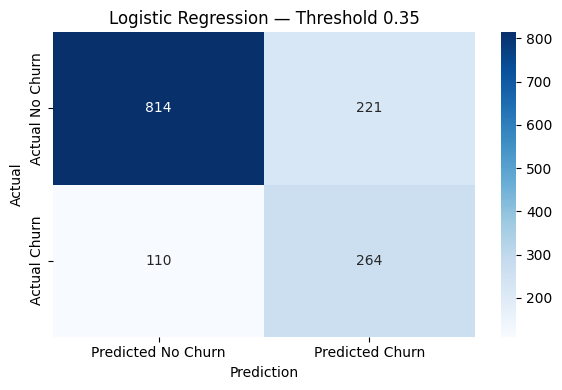

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns

# Fit the selected model on all training data
final_model = logistic_model.fit(X_train, y_train)

# Predict probabilities on the held-out test set
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
selected_threshold = 0.35
test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

# Evaluate
print("Threshold:", selected_threshold)
print("Accuracy :", round(
    accuracy_score(y_test, test_predictions), 4
))
print("Precision:", round(
    precision_score(y_test, test_predictions), 4
))
print("Recall   :", round(
    recall_score(y_test, test_predictions), 4
))
print("F1-score :", round(
    f1_score(y_test, test_predictions), 4
))
print("ROC-AUC  :", round(
    roc_auc_score(y_test, test_probabilities), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["No Churn", "Churn"]
))

cm = confusion_matrix(y_test, test_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted No Churn", "Predicted Churn"],
    yticklabels=["Actual No Churn", "Actual Churn"]
)
plt.title("Logistic Regression — Threshold 0.35")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()